# Phase 0 — Data audit (CCLE 2019 metabolomics × RNA-seq)

Implements `docs/research_plan.md` §4. **No modelling and no metabolite→gene mapping happen here.**

This notebook is a thin layer over `src/phase0/`. It (re)builds and **freezes** the Phase 0 tables in `data/processed/` and then shows the audit statistics.

* Prerequisite: `make data` (downloads + Cellosaurus cache; `Model.csv` is a manual download, see `docs/data_sources.md`).
* Run headless: `make audit`.

In [1]:
import os, sys, json
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src.phase0 import run, load, sources

pd.set_option("display.max_rows", 200, "display.max_colwidth", 120, "display.width", 200)

# chart style: one hue for single-series magnitude, recessive chrome
BLUE, ORANGE = "#2a78d6", "#eb6834"
SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.titlecolor": INK, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.axisbelow": True, "font.size": 9, "figure.dpi": 110,
})

def hbar(series, title, xlabel, ax=None, annotate=True, sort=True):
    """Horizontal bars; largest at top when sorted, else first item at top."""
    s = series.sort_values() if sort else series.iloc[::-1]
    ax = ax or plt.subplots(figsize=(7, 0.26 * len(s) + 0.9))[1]
    ax.barh(s.index.astype(str), s.values, color=BLUE, height=0.7, edgecolor=SURFACE, linewidth=1)
    ax.grid(axis="y", visible=False)
    ax.set_title(title, loc="left"); ax.set_xlabel(xlabel)
    if annotate:
        for y, v in enumerate(s.values):
            ax.text(v, y, f" {v:,}", va="center", ha="left", fontsize=8, color=INK2)
        ax.set_xlim(0, s.max() * 1.12)
    return ax

## 1. Data sources and checksums
`data/raw/MANIFEST.tsv` is written by `src/phase0/download.py`; this cell re-hashes every file and fails on mismatch.

In [2]:
from src.phase0 import download
assert download.main(["--verify"]) == 0, "raw data missing or checksum mismatch"
man = pd.read_csv(sources.MANIFEST, sep="\t", dtype=str)
man[man.key != "cellosaurus"][["key", "path", "release", "bytes", "sha256", "http_last_modified", "retrieved_utc"]]

[metabolomics] data/raw/ccle2019/CCLE_metabolomics_20190502.csv
  ok sha256=7c1d24aa575f... bytes=2,098,255
[rnaseq_tpm] data/raw/ccle2019/CCLE_RNAseq_rsem_genes_tpm_20180929.txt.gz


  ok sha256=612d2e608736... bytes=66,221,681
[annotations] data/raw/ccle2019/Cell_lines_annotations_20181226.txt
  ok sha256=77648d1cada2... bytes=335,355
[li2019_supp1] data/raw/li2019/41591_2019_404_MOESM2_ESM.xlsx
  ok sha256=214a31514d81... bytes=25,133,786
[model] data/raw/depmap/Model.csv
  ok (manual) sha256=65eb1895800e... release=DepMap Public 26Q3 (from depmap/README.txt header; Model.csv schema matches README)
[model_readme] data/raw/depmap/README.txt
  ok (manual) sha256=5672d9e04f18... release=DepMap Public 26Q3 (from depmap/README.txt header; Model.csv schema matches README)


,key,path,release,bytes,sha256,http_last_modified,retrieved_utc
0,rnaseq_tpm,data/raw/ccle2019/CCLE_RNAseq_rsem_genes_tpm_20180929.txt.gz,CCLE 2019 (RNA-seq RSEM gene TPM 2018-09-29; GENCODE v19),66221681,612d2e6087364fa89d57e22676a1429f58fa3bf001dfbbe1b16addb9102c651b,"Wed, 02 Jan 2019 15:18:14 GMT",2026-11-16T12:52:07Z
1,metabolomics,data/raw/ccle2019/CCLE_metabolomics_20190502.csv,CCLE 2019 (metabolomics 2019-05-02),2098255,7c1d24aa575f4c58a29019026b5df8e6d1142a56925aba32ff3f1d1d5a7fd0ac,"Thu, 02 May 2019 18:40:49 GMT",2026-11-16T12:49:55Z
2,annotations,data/raw/ccle2019/Cell_lines_annotations_20181226.txt,CCLE 2019 (cell line annotations 2018-12-26),335355,77648d1cada2f325ba2c049a5fb5408434f73b963c8e1148fb82ba2653e469e1,"Mon, 11 Feb 2019 18:28:17 GMT",2026-11-16T12:52:08Z
23,model,data/raw/depmap/Model.csv,DepMap Public 26Q3 (from depmap/README.txt header; Model.csv schema matches README),789805,65eb1895800e71a963a3ab56e5d08c8d006cb0d9e7aa68f7e34a3810a2a3cbc7,NaN,2026-11-16T12:45:29Z (file mtime)
24,model_readme,data/raw/depmap/README.txt,DepMap Public 26Q3 (from depmap/README.txt header; Model.csv schema matches README),48405,5672d9e04f18320e9ca1d25747427275dcabb44bffe45eba34d196f1b44dd3ec,NaN,2026-11-16T13:10:54Z (file mtime)
25,li2019_supp1,data/raw/li2019/41591_2019_404_MOESM2_ESM.xlsx,Li et al. 2019 Supplementary Tables (Supp. Table 1 sheets '1-*'),25133786,214a31514d813687c2c7b0786c0c57e8c6fc9aaafc3a160418c06774a73f3fea,"Tue, 14 Nov 2023 18:38:13 GMT",2026-11-16T12:52:26Z


In [3]:
cello = man[man.key == "cellosaurus"]
print(f"Cellosaurus cache: {len(cello)} files, release: {cello.release.iloc[0]}")
print("DepMap Model.csv release:", load.model_release())

Cellosaurus cache: 20 files, release: Cellosaurus 57.0 (2026-10-22)
DepMap Model.csv release: DepMap Public 26Q3 (from depmap/README.txt header; Model.csv schema matches README)


## 2. Build and freeze the Phase 0 tables

In [4]:
out = run.run(write=True)
S = out["summary"]; cells_df = out["cells"]; prim = cells_df[cells_df.in_primary_set]
pd.read_csv(sources.PROCESSED / "FREEZE.tsv", sep="\t")

,file,sha256,bytes
0,data/processed/cell_lines_phase0.csv,d6c627057d920587a6453523dc083025a105dabcce3af2ef1ddc532c53e034c1,405818
1,data/processed/medium_normalization.csv,d7c2c9cc6f30eec16b8e981fc8e3b709820c5be2e17d6846e459d4d385b3e5f6,28216
2,data/processed/medium_source_agreement.csv,e4b3d52778724624aba4cef3049c0c0c6a36b5d911a8e12f83bfe7d2357ed79d,741
3,data/processed/metabolite_inventory.csv,942e999d9781d2f6022ee367aa73740598807833a85f798c149fc2dbaf9b913c,31399
4,data/processed/id_issues.csv,39780b05b5eba6f5831f0cc5ca285974b81088d3a3da9eb35b6df9da32393b20,28623
5,data/processed/attrition.csv,a6d805d523aeb96f1d7ddb00a3467ea905b1a1d91eb9b16dfe2bb34fb1431649,400
6,data/processed/audit_summary.json,1b6b7177c41c189154a1123d5412c2765a74402239edb18df1d2484eb5643cac,4821


## 3. Acceptance criteria (go/no-go, research_plan §4)

In [5]:
g = S["gates"]
gates = pd.DataFrame([
    {"criterion": "≥ 400 matched solid-tumour lines (metabolomics + RNA-seq + lineage + medium)",
     "value": g["n_primary_lines"], "threshold": g["gate_min_primary_lines"],
     "result": "PASS" if g["gate_primary_lines_pass"] else "FAIL"},
    {"criterion": "≥ 90 % medium assignment coverage (of matched solid lines)",
     "value": f'{g["medium_coverage"]:.1%}', "threshold": "90%",
     "result": "PASS" if g["gate_medium_coverage_pass"] else "FAIL"},
    {"criterion": "≥ 15 confidently mapped polar targets", "value": "—", "threshold": 15,
     "result": "deferred to Phase 1"},
])
gates

,criterion,value,threshold,result
0,≥ 400 matched solid-tumour lines (metabolomics + RNA-seq + lineage + medium),735,400,PASS
1,≥ 90 % medium assignment coverage (of matched solid lines),100.0%,90%,PASS
2,≥ 15 confidently mapped polar targets,—,15,deferred to Phase 1


## 4. Cell-line matching and attrition

,step,n_lines
0,CCLE 2019 metabolomics lines,928
1,... with a DepMap ID,928
2,... found in current Model.csv (ModelID or alias),928
3,... with CCLE 2019 RNA-seq,913
4,... with lineage (OncotreeLineage),913
5,... duplicate cell lines removed (DepMap-merged IDs),912
6,... cancer models (non-cancerous/fibroblast removed),896
7,... solid tumour (Lymphoid/Myeloid removed),735
8,... with medium assigned = PRIMARY SET,735


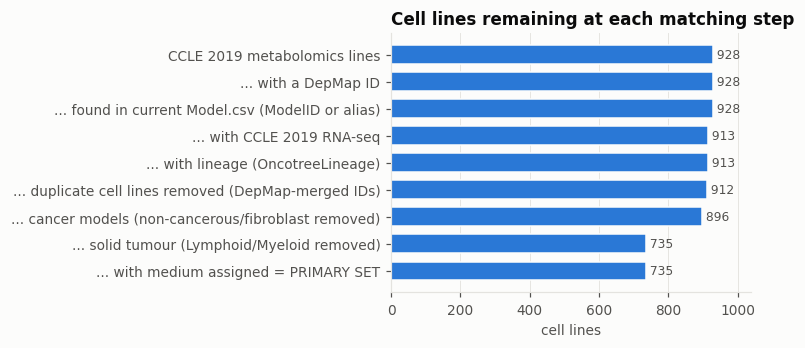

In [6]:
att = out["attrition"]; display(att)
hbar(att.set_index("step")["n_lines"], "Cell lines remaining at each matching step", "cell lines", sort=False)
plt.tight_layout(); plt.show()

In [7]:
iss = out["issues"]
display(iss.issue.value_counts().rename("n").to_frame())
iss[~iss.issue.isin(["shared_donor_group", "cellosaurus_problematic"])]

,n
issue,
cellosaurus_problematic,51
shared_donor_group,41
non_cancerous_model,16
li2019_name_differs[annotations],15
no_ccle2019_rnaseq,15
ccle_name_changed_in_model_csv,4
duplicate_rrid,2
depmap_id_missing_in_metabolomics,1
depmap_id_retired_alias,1


,CCLE_ID,DepMap_ID,issue,detail,action
0,HCC1588_LUNG,ACH-001078,ccle_name_changed_in_model_csv,Model.csv CCLEName='LS513_LARGE_INTESTINE' (different cell line name),kept (DepMap ID consistent); lineage from Model.csv
1,KE97_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,ACH-000167,ccle_name_changed_in_model_csv,Model.csv CCLEName='KE97_STOMACH' (tissue suffix only),kept (DepMap ID consistent); lineage from Model.csv
2,NCIH1339_LUNG,ACH-000921,ccle_name_changed_in_model_csv,Model.csv CCLEName='NCIH157DM_LUNG' (different cell line name),kept (DepMap ID consistent); lineage from Model.csv
3,NCIH684_LIVER,ACH-000089,ccle_name_changed_in_model_csv,Model.csv CCLEName='NCIH684_LARGE_INTESTINE' (tissue suffix only),kept (DepMap ID consistent); lineage from Model.csv
55,OC315_OVARY,ACH-001144,depmap_id_missing_in_metabolomics,filled from 2019 annotation: ACH-001144,filled
56,HCC1588_LUNG,ACH-001078,depmap_id_retired_alias,ACH-001078 is listed as ModelIDAlias of ACH-000007 in current Model.csv,mapped to current ModelID
57,HCC1588_LUNG,ACH-001078,duplicate_cell_line,same current DepMap model (ACH-000007) as metabolomics line LS513_LARGE_INTESTINE,excluded from primary set; canonical line LS513_LARGE_INTESTINE kept
58,HCC1588_LUNG,None,duplicate_rrid,"CVCL_1386 shared by ['HCC1588_LUNG', 'LS513_LARGE_INTESTINE']",same donor group
59,LS513_LARGE_INTESTINE,None,duplicate_rrid,"CVCL_1386 shared by ['HCC1588_LUNG', 'LS513_LARGE_INTESTINE']",same donor group
60,TO175T_FIBROBLAST,ACH-000125,haematopoietic_flag_discordant,Model.csv lineage=Fibroblast; 2019 Site_Primary=haematopoietic_and_lymphoid_tissue,Model.csv lineage used


### Spot check of 20 random primary-set lines (seed 0)
Manual check of CCLE_ID ↔ DepMap ID ↔ current Model.csv name ↔ Cellosaurus name ↔ lineage ↔ medium (research_plan §10.2).

In [8]:
prim.sample(20, random_state=0)[["CCLE_ID", "DepMap_ID", "ModelID", "CCLEName", "cellosaurus_name", "lineage",
                                   "li2019_classification", "medium_raw_li2019", "medium_raw_anno2019", "medium_category"]]

,CCLE_ID,DepMap_ID,ModelID,CCLEName,cellosaurus_name,lineage,li2019_classification,medium_raw_li2019,medium_raw_anno2019,medium_category
234,HDQP1_BREAST,ACH-000643,ACH-000643,HDQP1_BREAST,HDQ-P1,Breast,breast,DMEM + 10% FBS,DMEM+10% FBS,DMEM
223,HCC4006_LUNG,ACH-000066,ACH-000066,HCC4006_LUNG,HCC4006,Lung,lung_NSC,RPMI 1640 + 10% FBS,RPMI-1640 + 10% FBS,RPMI-1640
15,A101D_SKIN,ACH-000008,ACH-000008,A101D_SKIN,A101D,Skin,melanoma,DMEM + 10% FBS,NaN,DMEM
37,ASPC1_PANCREAS,ACH-000222,ACH-000222,ASPC1_PANCREAS,AsPC-1,Pancreas,pancreas,RPMI 1640 + 10% FBS,RPMI-1640 10% FBS +1 mM Sodium pyruvate,RPMI-1640
520,NCIH1618_LUNG,ACH-000179,ACH-000179,NCIH1618_LUNG,NCI-H1618,Lung,lung_small_cell,DMEM:F12 = 1:1 + 5% FBS,DMEM:HAM's F12 1:1 +5% FBS,DMEM:F12
418,LMSU_STOMACH,ACH-000255,ACH-000255,LMSU_STOMACH,LMSU,Esophagus/Stomach,stomach,F10 + 10% FBS,HamF10 +10% FBS,other
391,KS1_CENTRAL_NERVOUS_SYSTEM,ACH-000631,ACH-000631,KS1_CENTRAL_NERVOUS_SYSTEM,KS-1 [Human glioblastoma],CNS/Brain,glioma,MEM + 10% FBS,NaN,EMEM/MEM
911,VMRCRCZ_KIDNEY,ACH-000171,ACH-000171,VMRCRCZ_KIDNEY,VMRC-RCZ,Kidney,kidney,EMEM + 10% FBS,EMEM + 10% FBS,EMEM/MEM
593,NCIH660_PROSTATE,ACH-000177,ACH-000177,NCIH660_PROSTATE,NCI-H660,Prostate,prostate,RPMI 1640 + 5% FBS,NaN,RPMI-1640
30,ACHN_KIDNEY,ACH-000046,ACH-000046,ACHN_KIDNEY,ACHN,Kidney,kidney,EMEM + 10% FBS,EMEM +10%FBS,EMEM/MEM


## 5. Lineage distribution (primary set)
Lineages with < 15 primary-set lines are collapsed into `Other`.

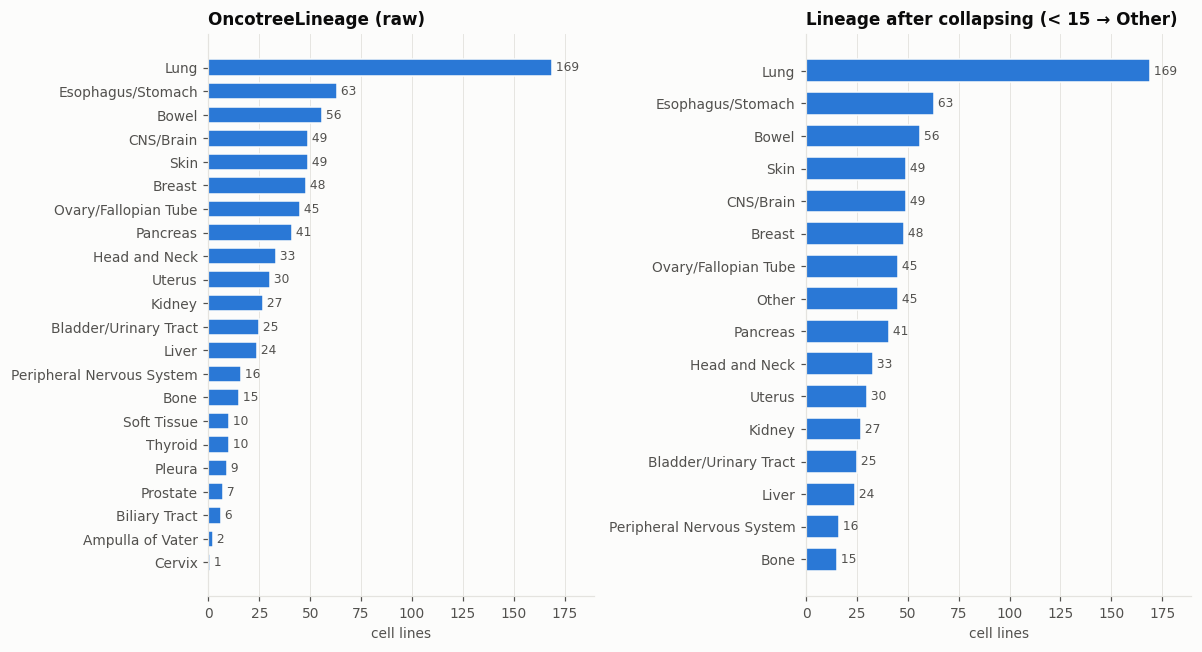

Collapsed into Other: Soft Tissue (10), Thyroid (10), Pleura (9), Prostate (7), Biliary Tract (6), Ampulla of Vater (2), Cervix (1)


In [9]:
lc = prim.lineage.value_counts()
fig, axes = plt.subplots(1, 2, figsize=(11, 6), gridspec_kw={"width_ratios": [1, 1]})
hbar(lc, "OncotreeLineage (raw)", "cell lines", ax=axes[0])
hbar(prim.lineage_collapsed.value_counts(), "Lineage after collapsing (< 15 → Other)", "cell lines", ax=axes[1])
plt.tight_layout(); plt.show()
print("Collapsed into Other:", ", ".join(f"{k} ({v})" for k, v in lc[lc < 15].items()))

In [10]:
print("Growth pattern (Model.csv) in primary set:"); display(prim.growth_pattern.value_counts(dropna=False).to_frame())
print("Excluded haematopoietic lines with RNA-seq:", int((cells_df.has_rnaseq & cells_df.is_haematopoietic & ~cells_df.is_non_cancerous).sum()))

Growth pattern (Model.csv) in primary set:


,count
growth_pattern,
Adherent,633
Mixed,55
Suspension,44
Unknown,3


Excluded haematopoietic lines with RNA-seq: 161


## 6. Culture medium
Source preference: Li et al. 2019 Supp. Table 1 → fallback 2019 `Growth.Medium`. Rules: `src/phase0/medium.py` (tested in `tests/test_medium.py`).

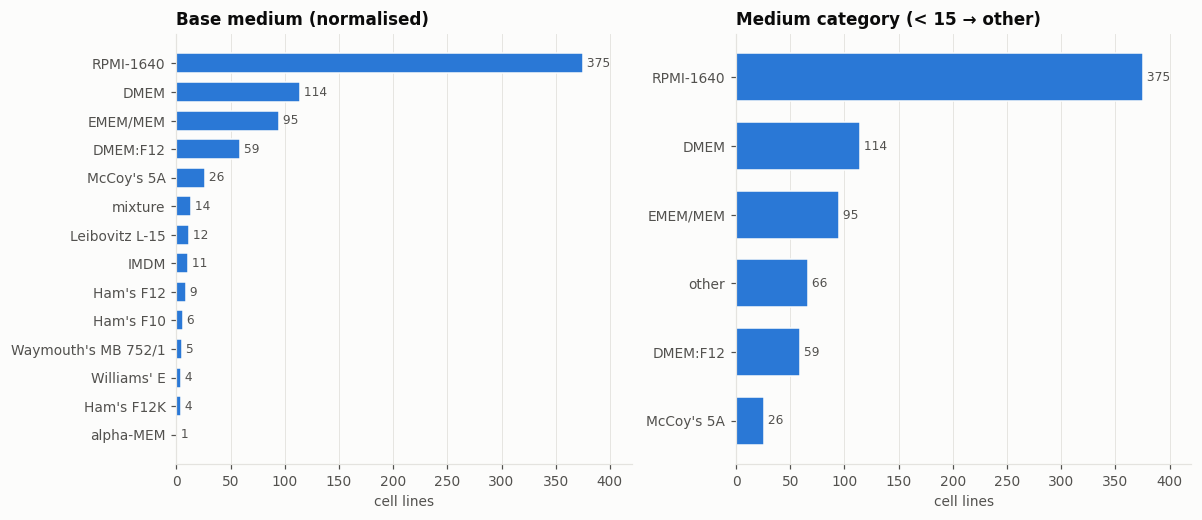

,count
medium_source,
li2019_supp1,735


Agreement Li vs 2019 annotation (both assigned, n=546): 99.5%


medium_base_anno2019,ACL-4,DMEM,DMEM:F12,EMEM/MEM,Ham's F10,Ham's F12,Ham's F12K,IMDM,Leibovitz L-15,McCoy's 5A,RPMI-1640,Waymouth's MB 752/1,Williams' E,alpha-MEM,mixture
medium_base_li2019,,,,,,,,,,,,,,,
DMEM,1,79,0,1,0,0,0,0,0,0,0,0,0,0,0
DMEM:F12,0,0,43,0,0,0,0,0,0,0,0,0,0,0,0
EMEM/MEM,0,1,0,68,0,0,0,0,0,0,0,0,0,0,0
Ham's F10,0,0,0,0,5,0,0,0,0,0,0,0,0,0,0
Ham's F12,0,0,0,0,0,7,0,0,0,0,0,0,0,0,0
Ham's F12K,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0
IMDM,0,0,0,0,0,0,0,5,0,0,0,0,0,0,0
Leibovitz L-15,0,0,0,0,0,0,0,0,8,0,0,0,0,0,0
McCoy's 5A,0,0,0,0,0,0,0,0,0,12,0,0,0,0,0


,CCLE_ID,medium_raw_li2019,medium_raw_anno2019
3,253J_URINARY_TRACT,DMEM + 10% FBS,Eagle
184,GB1_CENTRAL_NERVOUS_SYSTEM,EMEM + 10% FBS,Dulbecco's modified Eagle's medium with 10% fetal calf serum
595,NCIH684_LIVER,DMEM + 10% FBS,ACL-4


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
hbar(prim.medium_base.value_counts(), "Base medium (normalised)", "cell lines", ax=axes[0])
hbar(prim.medium_category.value_counts(), "Medium category (< 15 → other)", "cell lines", ax=axes[1])
plt.tight_layout(); plt.show()
display(prim.medium_source.value_counts().to_frame())
print(f'Agreement Li vs 2019 annotation (both assigned, n={g["medium_agreement_n_both"]}): {g["medium_agreement_frac"]:.1%}')
display(out["medium_agreement"])
prim[prim.medium_sources_agree.eq(False)][["CCLE_ID", "medium_raw_li2019", "medium_raw_anno2019"]]

In [12]:
norm = out["medium_normalization"]
print("unique raw strings:", norm.groupby("source").size().to_dict())
assert set(cells_df.medium_raw_li2019.dropna()) <= set(norm.raw_string)
assert set(cells_df.medium_raw_anno2019.dropna()) <= set(norm.raw_string)
norm[norm.source == "li2019_supp1"][["raw_string", "n_lines", "n_lines_primary", "medium_base", "components", "medium_category_primary"]]

unique raw strings: {'anno2019_growth_medium': 216, 'li2019_supp1': 42}


,raw_string,n_lines,n_lines_primary,medium_base,components,medium_category_primary
216,DMEM + 10% FBS,108,93,DMEM,DMEM,DMEM
217,DMEM + 20% FBS,10,9,DMEM,DMEM,DMEM
218,DMEM + 15% FBS,7,7,DMEM,DMEM,DMEM
219,DMEM + 5% FBS,5,5,DMEM,DMEM,DMEM
220,DMEM:F12 = 1:1 + 10% FBS,35,34,DMEM:F12,DMEM+Ham's F12,DMEM:F12
221,DMEM:F12 = 1:1 + 5% FBS,21,20,DMEM:F12,DMEM+Ham's F12,DMEM:F12
222,DMEM:F12 = 1:1 + 20% FBS,4,4,DMEM:F12,DMEM+Ham's F12,DMEM:F12
223,DMEM:F12 = 1:1 + 15% FBS,1,1,DMEM:F12,DMEM+Ham's F12,DMEM:F12
224,EMEM + 10% FBS,68,64,EMEM/MEM,EMEM/MEM,EMEM/MEM
225,MEM + 10% FBS,15,14,EMEM/MEM,EMEM/MEM,EMEM/MEM


In [13]:
print("Serum % (informational; not used):"); prim.serum_pct.value_counts(dropna=False).sort_index().to_frame()

Serum % (informational; not used):


,count
serum_pct,
5.0,39
10.0,615
15.0,31
20.0,50


## 7. Duplicates, problematic lines and shared donors

In [14]:
print(json.dumps({k: S["primary_set"][k] for k in ["n_problematic", "n_multi_line_donor_groups", "n_in_multi_line_donor_groups"]}, indent=1))
display(prim[prim.is_problematic].problematic_type.value_counts().to_frame())
prim[prim.is_problematic][["CCLE_ID", "lineage", "problematic_type", "problematic_text"]].assign(
    problematic_text=lambda d: d.problematic_text.str.slice(0, 140))

{
 "n_problematic": 26,
 "n_multi_line_donor_groups": 11,
 "n_in_multi_line_donor_groups": 22
}


,count
problematic_type,
Misclassified,8
Contaminated,8
Partially contaminated,3
Probably misclassified,1
Probably misclassified/misidentified,1
Possibly misclassified,1
Misidentified/contaminated,1
Possibly misidentified,1
Possibly contaminated,1


,CCLE_ID,lineage,problematic_type,problematic_text
26,A673_BONE,Bone,Misclassified,Misclassified. Originally thought to be a rhabdomyosarcoma cell line but shown to be from an Ewing sarcoma (PubMed=1...
50,BICR18_UPPER_AERODIGESTIVE_TRACT,Head and Neck,Partially contaminated,"Partially contaminated. The ICLC stock (now discontinued) was found to be contaminated, probably by U-251MG (Cellosa..."
68,CAKI2_KIDNEY,Kidney,Misclassified,Misclassified. Originally thought to be a clear cell renal cell carcinoma but shown to be from a papillary renal cel...
113,COLO741_SKIN,Skin,Misclassified,Misclassified. Originally thought to be a colon adenocarcinoma cell line but shown to be from a melanoma (PubMed=259...
128,COV434_OVARY,Ovary/Fallopian Tube,Misclassified,Misclassified. Originally thought to be an ovarian granulosa cell tumor but seems to be a small cell carcinoma of th...
170,ES2_OVARY,Ovary/Fallopian Tube,Probably misclassified,Probably misclassified. It is dubious that this cell line originates from an African American 47 year old patient di...
180,G401_SOFT_TISSUE,Kidney,Misclassified,Misclassified. Originally thought to be a Wilms tumor cell line but is a kidney rhabdoid tumor cell line (PubMed=838...
190,GOS3_CENTRAL_NERVOUS_SYSTEM,CNS/Brain,Contaminated,Contaminated. Shown to be a U-343MGa derivative (PubMed=22570425). Originally thought to originate from the brain of...
225,HCC56_LARGE_INTESTINE,Bowel,Contaminated,Contaminated. Shown to be a HSC-57 derivative (JCRB=JCRB1037). Originally thought to originate from a colon adenocar...
247,HEPG2_LIVER,Liver,Misclassified,Misclassified. Originally thought to be a hepatocellular carcinoma cell line but shown to be from an hepatoblastoma ...


In [15]:
grp = cells_df[cells_df.donor_group_size > 1].sort_values(["donor_group_id", "CCLE_ID"])
grp[["donor_group_id", "CCLE_ID", "lineage", "in_primary_set", "donor_group_size_primary", "donor_link_reason"]]

,donor_group_id,CCLE_ID,lineage,in_primary_set,donor_group_size_primary,donor_link_reason
2,DG001,253JBV_URINARY_TRACT,Bladder/Urinary Tract,True,2,Cellosaurus HI (derived from); same DepMap PatientID
3,DG001,253J_URINARY_TRACT,Bladder/Urinary Tract,True,2,Cellosaurus HI (derived from); same DepMap PatientID
15,DG002,A101D_SKIN,Skin,True,2,Cellosaurus HI (derived from); same DepMap PatientID
263,DG002,HS294T_SKIN,Skin,True,2,Cellosaurus HI (derived from); same DepMap PatientID
38,DG003,AU565_BREAST,Breast,True,2,Cellosaurus OI (same individual); same DepMap PatientID
735,DG003,SKBR3_BREAST,Breast,True,2,Cellosaurus OI (same individual); same DepMap PatientID
91,DG004,CGTHW1_THYROID,Head and Neck,False,1,Cellosaurus HI (derived from); Cellosaurus problematic: shown to be derivative; same DepMap PatientID
847,DG004,SW579_THYROID,Head and Neck,True,1,Cellosaurus HI (derived from); Cellosaurus problematic: shown to be derivative; same DepMap PatientID
93,DG005,CHL1_SKIN,Skin,False,1,same DepMap PatientID
255,DG005,HMCB_SKIN,Skin,True,1,same DepMap PatientID


## 8. Metabolomics: panel, format, transformation, missingness

In [16]:
print(json.dumps(S["metabolomics_format"], indent=1))
print(json.dumps(S["metabolite_inventory"], indent=1))

{
 "csv_shape": [
  928,
  225
 ],
 "clean_sheet_shape": [
  928,
  225
 ],
 "rows_matched_csv_vs_clean": 928,
 "cols_matched_csv_vs_clean": 225,
 "max_abs_diff_csv_vs_clean": 0.0,
 "raw_rows_matched": 928,
 "raw_missing_cells": 19185,
 "raw_missing_frac": 0.09188218,
 "raw_missing_filled_in_csv": 19185,
 "median_corr_clean_vs_log10raw": 0.89844907,
 "min_corr_clean_vs_log10raw": 0.25806071,
 "median_corr_clean_vs_linear_raw": 0.72588869,
 "median_slope_clean_on_log10raw": 0.76879502,
 "iqr_slope": [
  0.68120587,
  0.86299004
 ],
 "value_min": 2.9760308,
 "value_p01": 4.78354014,
 "value_median": 5.8839763,
 "value_p99": 6.94161753,
 "value_max": 9.0989016,
 "n_metabolites_corr_computed": 225
}
{
 "polar_sheet_names_unused": [],
 "n_polar_transitions_in_sheet": 137,
 "n_lipid_rows_in_sheet": 89,
 "assay_class_counts": {
  "lipid (RPLC)": 89,
  "polar (HILIC)": 136
 },
 "polar_ion_mode_counts": {
  "negative": 59,
  "positive": 77
 },
 "n_names_with_slash": 13,
 "n_polar_carnitines": 1

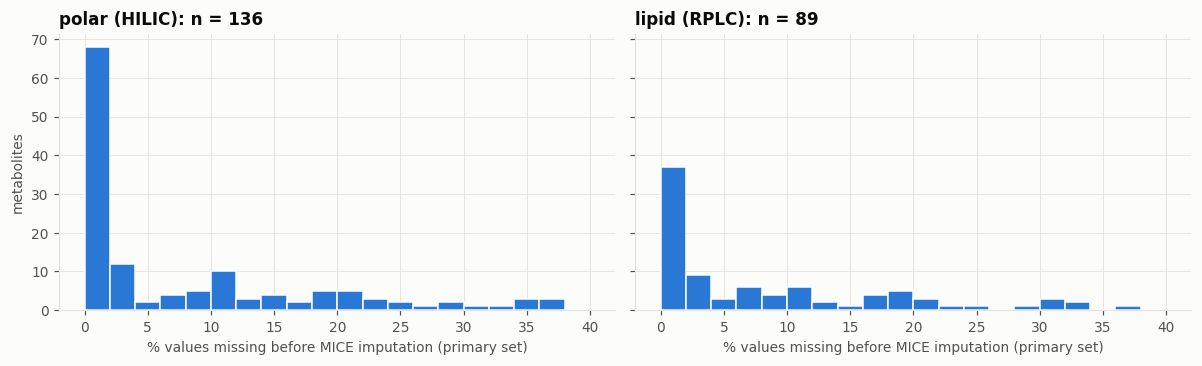

,metabolite,assay_class,ion_mode,raw_missing_frac_primary,li2019_cv,sd_primary
192,C46:2 TAG,lipid (RPLC),,0.375510,0.036382,0.375875
54,alpha-hydroxybutyrate,polar (HILIC),negative,0.374150,0.039416,0.198651
100,acetylcholine,polar (HILIC),positive,0.363265,0.208064,0.906405
48,taurocholate,polar (HILIC),negative,0.360544,0.038299,0.343706
133,sarcosine,polar (HILIC),positive,0.348299,0.047390,0.256689
111,cAMP,polar (HILIC),negative,0.348299,0.047035,0.285364
105,hexoses (HILIC pos),polar (HILIC),positive,0.340136,0.043581,0.381801
157,C36:4 PC-A,lipid (RPLC),,0.326531,0.016587,0.244303
170,C18:2 SM,lipid (RPLC),,0.323810,0.014886,0.263783
132,arachidonyl_carnitine,polar (HILIC),positive,0.321088,0.049272,0.257352


In [17]:
inv = out["metabolite_inventory"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, cls in zip(axes, ["polar (HILIC)", "lipid (RPLC)"]):
    v = inv.loc[inv.assay_class == cls, "raw_missing_frac_primary"] * 100
    ax.hist(v, bins=np.arange(0, 42, 2), color=BLUE, edgecolor=SURFACE, linewidth=1)
    ax.set_title(f"{cls}: n = {len(v)}", loc="left"); ax.set_xlabel("% values missing before MICE imputation (primary set)")
axes[0].set_ylabel("metabolites"); plt.tight_layout(); plt.show()
inv.sort_values("raw_missing_frac_primary", ascending=False).head(20)[
    ["metabolite", "assay_class", "ion_mode", "raw_missing_frac_primary", "li2019_cv", "sd_primary"]]

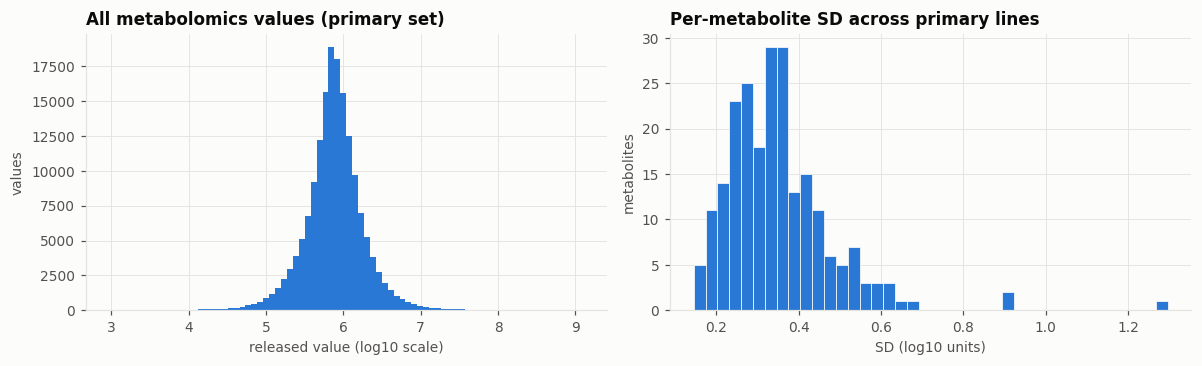

per-metabolite means: min 5.59, median 5.88, max 6.07  -> each metabolite re-centred; compare within metabolite only


In [18]:
X = load.load_metabolomics().set_index("CCLE_ID").drop(columns="DepMap_ID").loc[prim.CCLE_ID]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].hist(X.values.ravel(), bins=80, color=BLUE)
axes[0].set_title("All metabolomics values (primary set)", loc="left"); axes[0].set_xlabel("released value (log10 scale)"); axes[0].set_ylabel("values")
axes[1].hist(inv.sd_primary, bins=40, color=BLUE, edgecolor=SURFACE, linewidth=0.5)
axes[1].set_title("Per-metabolite SD across primary lines", loc="left"); axes[1].set_xlabel("SD (log10 units)"); axes[1].set_ylabel("metabolites")
plt.tight_layout(); plt.show()
print("per-metabolite means: min %.2f, median %.2f, max %.2f  -> each metabolite re-centred; compare within metabolite only"
      % (inv.mean_primary.min(), inv.mean_primary.median(), inv.mean_primary.max()))

In [19]:
inv[inv.name_has_slash][["metabolite", "assay_class", "lcms_sheet_name"]]

,metabolite,assay_class,lcms_sheet_name
15,DHAP/glyceraldehyde 3P,polar (HILIC),dihydroxyacetone phosphate (DHAP); glyceraldehyde-3-phosphate
17,F1P/F6P/G1P/G6P,polar (HILIC),hexose monophosphate (F1P/F6P/G1P/G6P)
19,fumarate/maleate/alpha-ketoisovalerate,polar (HILIC),fumarate/maleate/alpha-ketoisovalerate
37,ribose-5-P/ribulose5-P,polar (HILIC),ribose-5-P/ribulose5-P
39,succinate/methylmalonate,polar (HILIC),succinate/methylmalonate
43,UDP-galactose/UDP-glucose,polar (HILIC),UDP-galactose/UDP-glucose
49,glycodeoxycholate/glycochenodeoxycholate,polar (HILIC),glycodeoxycholate/glycochenodeoxycholate
50,taurodeoxycholate/taurochenodeoxycholate,polar (HILIC),taurodeoxycholate/taurochenodeoxycholate
52,3-methyladipate/pimelate,polar (HILIC),3-methyladipate/pimelate
77,cis/trans-hydroxyproline,polar (HILIC),cis/trans-hydroxyproline


## 9. Expression (CCLE 2019 RSEM gene TPM)

In [20]:
print(json.dumps(S["expression_format"], indent=1))
cs = out["rnaseq_colsum"]; print("TPM column sums: min %.1f, max %.1f (linear TPM, not log)" % (cs.min(), cs.max()))

{
 "n_genes": 57820,
 "n_lines": 1019,
 "n_ensg_versioned_ids": 57773,
 "n_ensgr_par_y_ids": 47,
 "n_other_ids": 0,
 "n_duplicate_ids_after_version_strip": 0,
 "n_nan": 0,
 "n_negative": 0,
 "max_value": 225730.0,
 "colsum_min": 999994.5625,
 "colsum_median": 1000000.125,
 "colsum_max": 1000006.0,
 "frac_zero": 0.54381317,
 "n_primary_lines": 735,
 "n_genes_mean_log2tpm1_ge1_primary": 15106,
 "n_genes_all_zero_primary": 8769,
 "duplicate_line_columns": 0,
 "n_ensgr_with_ensg_counterpart": 47,
 "n_ensgr_all_zero_all_lines": 47,
 "n_genes_after_dropping_ensgr": 57773
}
TPM column sums: min 999994.6, max 1000006.0 (linear TPM, not log)


## 10. Integrity assertions

In [21]:
assert not cells_df.CCLE_ID.duplicated().any()
assert not prim.DepMap_ID.duplicated().any() and not prim.ModelID.duplicated().any()
assert prim[["lineage", "medium_base"]].notna().all().all()
assert prim.has_rnaseq.all() and prim.has_metabolomics.all() and prim.in_model.all()
assert (~prim.medium_base.isin(["unknown", "ambiguous"])).all()
assert not prim.is_haematopoietic.any() and not prim.is_non_cancerous.any() and not prim.is_duplicate_line.any()
assert S["metabolomics_format"]["max_abs_diff_csv_vs_clean"] < 1e-9
print("all assertions passed")

all assertions passed
